# TalentBridge — Resume Screening and Role Matching
## Purpose and execution
Run this notebook beside `parsed_resumes.csv` using Restart Kernel and Run All. Requires pandas, numpy, matplotlib and scikit-learn. Outputs go into `capstone_outputs_v2`.

Primary approach: transparent structured requirement scoring plus TF-IDF similarity (Option 1 with explicit business rules). Three classifiers demonstrate reproduction of synthetic rule labels; their probabilities are **not blended into the ranking**. This removes the unsupported rule/ML hybrid.

This is recruiter decision support, not automated rejection. Job configurations, skill vocabulary, scoring weights and thresholds are learner assumptions. Two assumed roles are examined; no claim of real hiring accuracy, fairness or production readiness is made. The supplied data dictionary guides field interpretation. Certifications have no dedicated field and education is not scored without a specified job requirement. Names, filenames, institution tier and presentation-quality metadata do not affect suitability.

In [1]:
# Step 1: Import project libraries
from pathlib import Path
import json, re
from collections import Counter
from difflib import SequenceMatcher
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display as _display, HTML, Image
from sklearn.base import BaseEstimator, TransformerMixin

In [2]:
# Step 2: Import project libraries
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [3]:
# Step 3: Define display
def display(x):
    _display(HTML(x.to_html() if isinstance(x,(pd.DataFrame,pd.Series)) else str(x)))
SEED=42
OUT=Path('capstone_outputs_final'); OUT.mkdir(exist_ok=True)
raw=pd.read_csv('parsed_resumes.csv')
df=raw.copy()
print('Shape:',df.shape)
display(df.head(3))

Shape: (5000, 34)


,candidate_id,resume_file_name,candidate_name,primary_domain,primary_role,years_experience,highest_education,education_field,institution_tier,technical_skills_raw,tools_platforms_raw,soft_skills_raw,experience_summary,project_summary,key_achievements,management_experience_flag,people_management_flag,project_management_experience_flag,agile_scrum_experience_flag,client_facing_experience_flag,delivery_lead_experience_flag,cloud_experience_flag,ml_experience_flag,compliance_experience_flag,enterprise_systems_experience_flag,offshore_onsite_model_experience_flag,multi_vendor_coordination_flag,process_compliance_experience_flag,documentation_heavy_role_flag,mentoring_experience_flag,stakeholder_management_experience_flag,resume_length_words,keyword_density_score,profile_completeness_score
0,CND_100001,DataAnalyst_1.pdf,Candidate_1,Data Science,Data Analyst,7,LLM,Mathematics,Tier-1,"Machine Learning, Power BI, Pandas, Python","AWS, ServiceNow","Leadership, Teamwork","Hands-on data science professional with 7+ years of end-to-end delivery experience spanning design, development, testing and release.","Delivered project components on time and within scope, coordinating with teams in offshore and onsite locations.",Supported initiatives that increased team productivity by 9% and reduced rework or delays.,0,0,1,1,1,0,0,1,0,1,1,1,1,0,1,1,56,0.74,0.61
1,CND_100002,profile_2.pdf,Candidate_2,IT,Senior Software Engineer,10,Masters,Computer Science,Tier-2,"Kubernetes, Git, Docker, Python","AWS, Jira","Teamwork, Communication","Over 10 years delivering solutions in it, collaborating with cross-functional teams and stakeholders to meet business goals.","Led implementation of it projects for enterprise clients, focusing on scalability, stability and performance.","Contributed to 43% improvement in key KPIs such as throughput, response time or customer satisfaction.",1,1,1,1,1,1,0,0,0,1,1,1,1,1,1,1,54,0.89,0.89
2,CND_100003,Legal_candidate_3.pdf,Candidate_3,Legal,Compliance Officer,7,LLM,Law,Tier-1,"Due Diligence, Legal Research, Compliance, Contract Drafting","ServiceNow, AWS","Teamwork, Leadership","Hands-on legal professional with 7+ years of end-to-end delivery experience spanning design, development, testing and release.","Delivered project components on time and within scope, coordinating with teams in offshore and onsite locations.",Improved process efficiency by 23% and helped reduce incidents or defects through better practices.,0,0,1,0,1,0,0,0,1,1,1,1,1,1,1,1,57,0.40,0.56


## 1. Validation and conservative cleaning
Range checks enforce numeric types, binary flags and 0–1 metadata. Missing or invalid values are flagged, not invented. Candidate IDs must be unique and present. Duplicate content is flagged, not deleted. Short summaries (<10 words) and unusual experience/title combinations trigger review only. There is no arbitrary resume-length suitability penalty: positive lengths are checked, and their observed range is reported for clarification. The seniority buckets are descriptive assumptions.

In [4]:
# Step 4: Prepare or inspect TEXT
TEXT=['technical_skills_raw','tools_platforms_raw','soft_skills_raw','experience_summary','project_summary','key_achievements']
FLAGS=[c for c in df if c.endswith('_flag')]
required=TEXT+['candidate_id','resume_file_name','primary_role','primary_domain','years_experience',
               'highest_education','education_field','resume_length_words','keyword_density_score','profile_completeness_score']
if set(required)-set(df): raise ValueError('Missing required columns: '+str(set(required)-set(df)))
audit=[]
def log(name,mask,action):audit.append({'check':name,'count':int(pd.Series(mask).sum()),'action':action})
log('Missing ID',df.candidate_id.isna(),'Resolve before processing')
log('Duplicate ID',df.candidate_id.duplicated(),'Resolve before processing')

In [5]:
# Step 5: Prepare or inspect if df.candidate_id.isna().any() or df.candidate_id.duplicated().a
if df.candidate_id.isna().any() or df.candidate_id.duplicated().any():raise ValueError('Resolve candidate IDs first')
df['data_review_flag']=False
for c in TEXT+['primary_role','primary_domain']:
    bad=df[c].isna()|df[c].fillna('').astype(str).str.strip().eq('')
    log('Missing/blank '+c,bad,'Preserve as empty; review')
    df['data_review_flag']|=bad
    df[c]=df[c].fillna('').astype(str).str.strip()

In [6]:
# Step 6: Run c processing
for c in ['highest_education','education_field']:
    bad=df[c].isna()|df[c].fillna('').str.strip().eq('')
    log('Missing '+c,bad,'Set Unknown; no suitability penalty')
    df.loc[bad,c]='Unknown'
for c,lo,hi in [('years_experience',0,60),('resume_length_words',1,np.inf),
                ('keyword_density_score',0,1),('profile_completeness_score',0,1)]:
    v=pd.to_numeric(df[c],errors='coerce');bad=v.isna()|~v.between(lo,hi)
    log('Invalid/missing '+c,bad,'Set missing; flag')
    df[c]=v.mask(bad);df['data_review_flag']|=bad

In [7]:
# Step 7: Run c processing
for c in FLAGS:
    v=pd.to_numeric(df[c],errors='coerce');bad=~v.isin([0,1])
    log('Invalid/missing '+c,bad,'Set missing; flag')
    df[c]=v.mask(bad);df['data_review_flag']|=bad

In [8]:
# Step 8: Run (name, mask) processing
for name,mask in {
    'duplicate_filename':df.resume_file_name.notna() & df.resume_file_name.duplicated(keep=False),
    'duplicate_content':df[TEXT].apply(lambda x:x.str.lower()).duplicated(keep=False),
    'short_summary':df.experience_summary.str.split().str.len().lt(10),
    'role_experience_anomaly':(df.primary_role.str.contains('junior',case=False)&df.years_experience.gt(10)) |
       (df.primary_role.str.contains('senior|lead|principal',case=False,regex=True)&df.years_experience.lt(3))
}.items():
    df[name+'_flag']=mask
    df['data_review_flag']|=mask
    log(name,mask,'Retain; review; no automatic rejection')

In [9]:
# Step 9: Prepare or inspect df['seniority_bucket']
df['seniority_bucket']=pd.cut(df.years_experience,[-1,2,5,10,np.inf],labels=['Entry','Mid','Senior','Lead']).astype('string').fillna('Unknown')
validation=pd.DataFrame(audit)
validation.to_csv(OUT/'validation_summary.csv',index=False)
display(validation)
df.to_csv(OUT/'cleaned_parsed_resumes.csv',index=False)

,check,count,action
0,Missing ID,0,Resolve before processing
1,Duplicate ID,0,Resolve before processing
2,Missing/blank technical_skills_raw,0,Preserve as empty; review
3,Missing/blank tools_platforms_raw,0,Preserve as empty; review
4,Missing/blank soft_skills_raw,0,Preserve as empty; review
5,Missing/blank experience_summary,0,Preserve as empty; review
6,Missing/blank project_summary,0,Preserve as empty; review
7,Missing/blank key_achievements,0,Preserve as empty; review
8,Missing/blank primary_role,0,Preserve as empty; review
9,Missing/blank primary_domain,0,Preserve as empty; review


## 2. Broad but conservative skill normalization
Frequency alone does not establish correctness. The fixed vocabulary below is a learner-reviewed vocabulary for this dataset, frozen before model splitting. It is not an employer-approved taxonomy.

Automatically repair only a **unique adjacent-letter transposition** or a whitespace-only variant of a known term. This covers `padnas`, `dcoker`, `powre bi`, and many related noise patterns without a loose fuzzy cutoff. Other close terms are suggestions only; preserve the raw token and send the profile for review. A manually verified alias map can be extended. Every unique token and decision is exported.

A missing parsed skill means 'not evidenced', not proof that the candidate lacks it. Even normalized matches are not verified proficiency.

In [10]:
# Step 10: Prepare or inspect VOCAB
VOCAB=set('machine learning|power bi|pandas|python|kubernetes|git|docker|due diligence|legal research|compliance|contract drafting|aws|sql|java|nlp|linux|recruitment|employee engagement|payroll|hrms|hr analytics|solidworks|cad|manufacturing|quality control|tensorflow|risk management|strategy|stakeholder management|agile|servicenow|jira|azure|gcp|confluence|deep learning|spark'.split('|'))
ALIASES={'ml':'machine learning','natural language processing':'nlp','amazon web services':'aws','python programming':'python'}
def tokens(s):return [re.sub(r'\s+',' ',t).strip().lower() for t in re.split(r'[,;|]',str(s)) if t.strip()]
def compact(s):return re.sub(r'\s+','',s)
def transpose_once(a,b):
    if len(a)!=len(b):return False
    diff=[i for i,(x,y) in enumerate(zip(a,b)) if x!=y]
    return len(diff)==2 and diff[1]==diff[0]+1 and a[diff[0]]==b[diff[1]] and a[diff[1]]==b[diff[0]]

In [11]:
# Step 11: Define decide
def decide(s):
    if s in VOCAB:return s,'canonical',''
    if s in ALIASES:return ALIASES[s],'explicit alias',''
    matches=[v for v in sorted(VOCAB) if compact(s)==compact(v) or transpose_once(compact(s),compact(v))]
    if len(matches)==1:return matches[0],'unique transposition/spacing',''
    ranked=sorted(((SequenceMatcher(None,s,v).ratio(),v) for v in VOCAB),reverse=True)
    suggestion=ranked[0][1] if ranked and ranked[0][0]>=.72 else ''
    return s,'unresolved',suggestion
counts=Counter(t for c in ['technical_skills_raw','tools_platforms_raw'] for x in df[c] for t in tokens(x))

In [12]:
# Step 12: Prepare or inspect rows
rows=[]
for t,count in sorted(counts.items()):
    normalized,method,suggestion=decide(t)
    rows.append({'raw_skill':t,'normalized_skill':normalized,'method':method,'suggestion_only':suggestion,'occurrences':count})
skill_audit=pd.DataFrame(rows)
MAP=skill_audit.set_index('raw_skill').normalized_skill.to_dict()
UNRESOLVED=set(skill_audit.loc[skill_audit.method.eq('unresolved'),'raw_skill'])
raw_lists=(df.technical_skills_raw+','+df.tools_platforms_raw).map(tokens)
df['normalized_skills']=raw_lists.map(lambda xs:set(MAP.get(x,x) for x in xs))

In [13]:
# Step 13: Prepare or inspect df['unresolved_skills']
df['unresolved_skills']=raw_lists.map(lambda xs:', '.join(sorted(set(xs)&UNRESOLVED)))
df['skill_review_flag']=df.unresolved_skills.ne('')
df['skill_count']=df.normalized_skills.map(len)
assert decide('padnas')[0]=='pandas' and decide('dcoker')[0]=='docker' and decide('powre bi')[0]=='power bi'
changed=skill_audit.raw_skill.ne(skill_audit.normalized_skill)
print('Unique skill variants corrected:',int(changed.sum()))
print('Unresolved unique terms:',len(UNRESOLVED))
display(skill_audit[changed].head(20))
skill_audit.to_csv(OUT/'skill_normalization_audit.csv',index=False)

Unique skill variants corrected: 182
Unresolved unique terms: 0


,raw_skill,normalized_skill,method,suggestion_only,occurrences
0,agiel,agile,unique transposition/spacing,,6
2,aglie,agile,unique transposition/spacing,,4
3,aigle,agile,unique transposition/spacing,,5
7,cmopliance,compliance,unique transposition/spacing,,5
8,comlpiance,compliance,unique transposition/spacing,,4
9,compilance,compliance,unique transposition/spacing,,3
10,complaince,compliance,unique transposition/spacing,,2
11,compliacne,compliance,unique transposition/spacing,,4
13,complianec,compliance,unique transposition/spacing,,5
14,complinace,compliance,unique transposition/spacing,,2


## 3. EDA and findings
Charts and findings describe this dataset, not a validated candidate population. Check template reuse and length-field meaning before generalizing. Quality metadata is reported but excluded from fit scores.

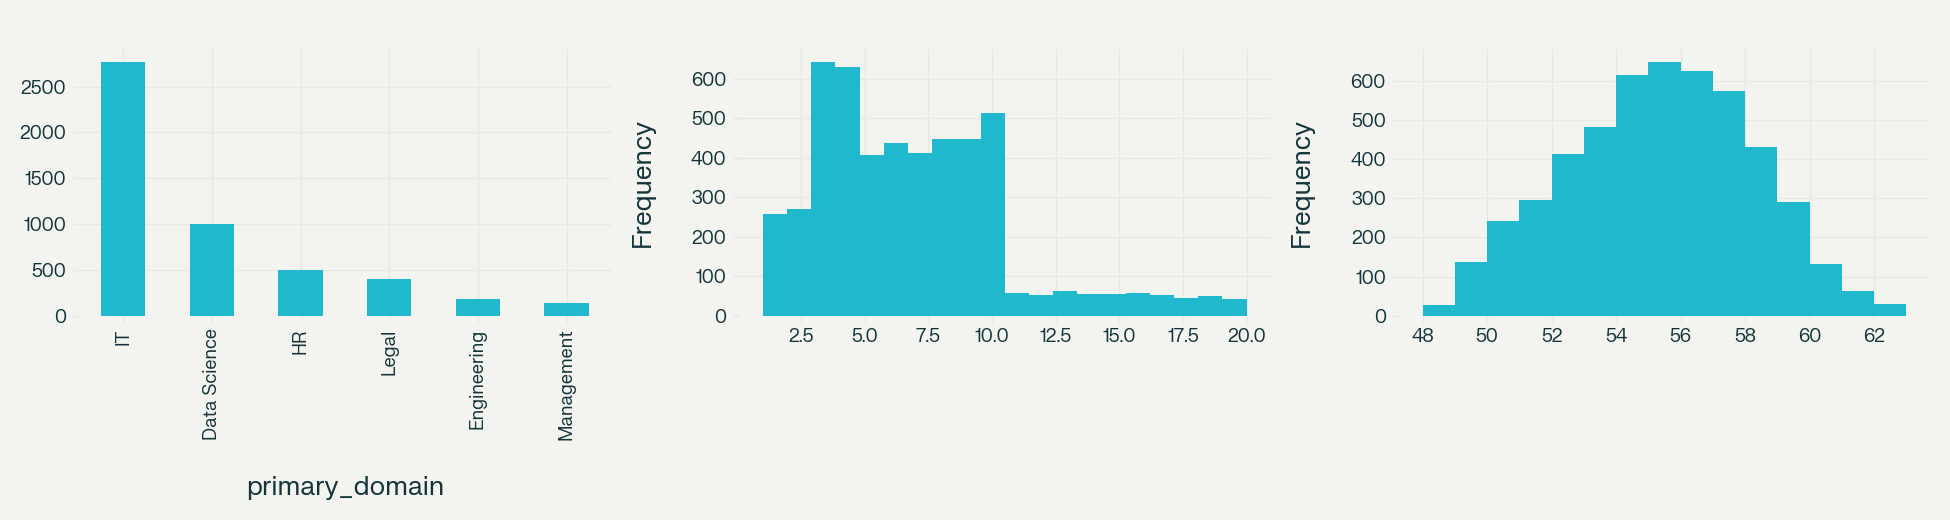

In [14]:
# Step 14: Prepare or inspect fig,axes
fig,axes=plt.subplots(1,3,figsize=(15,4))
df.primary_domain.value_counts().plot.bar(ax=axes[0],title='Domain distribution')
df.years_experience.plot.hist(ax=axes[1],bins=20,title='Experience in years')
df.resume_length_words.plot.hist(ax=axes[2],bins=15,title='Reported resume word count')
fig.tight_layout();fig.savefig(OUT/'eda.png',dpi=130);plt.close(fig); _display(Image(filename=str(OUT/'eda.png')))

In [15]:
# Step 15: Prepare or inspect findings
findings=[f'{len(df):,} candidates; {df.primary_domain.nunique()} domains.',
          f'Median experience: {df.years_experience.median():g} years.',
          f'Reported resume length: {df.resume_length_words.min():g}–{df.resume_length_words.max():g} words; field interpretation needs clarification.',
          f'{df.experience_summary.duplicated().sum()} repeated experience summaries; template reuse may dominate text similarity.',
          f'{int(changed.sum())} distinct skill variants normalized; {len(UNRESOLVED)} terms left unresolved.']
for x in findings:print('-',x)

- 5,000 candidates; 6 domains.
- Median experience: 6 years.
- Reported resume length: 48–63 words; field interpretation needs clarification.
- 4749 repeated experience summaries; template reuse may dominate text similarity.
- 182 distinct skill variants normalized; 0 terms left unresolved.


## 4. Transparent matching: two assumed jobs
Structural score: required skills 50%, minimum experience coverage 20%, domain 15%, related title 10%, delivery/leadership indicators 5%. NLP ranking score: 80% structural score + 20% TF-IDF cosine similarity (scaled to 100). These are transparent assumptions, not optimized weights or calibrated probabilities. Similarity remains on its original scale; no dataset-dependent min-max inflation is applied.

Eligibility requires all listed mandatory skills and minimum experience; domain/title are soft features. Optional skills are reported but are not double-counted in the structural score. High synthetic fit = eligible plus structural score >=80; Medium >=50; otherwise Low. Eligibility and review flags are reported independently. Neither eligibility nor High Fit means interview-ready.

Primary output uses rules + NLP only, not ML probabilities. Models below are a separate educational experiment. The two roles are illustrative, not evidence of generalization to real vacancies.

### Why these weights were chosen
Mandatory skills receive the largest structural weight because they represent explicit technical requirements. Experience receives the next largest weight because the role specifies a minimum. Domain and title are weaker supporting evidence so candidates with transferable experience can still be considered. Delivery indicators receive a small weight because they are unverified resume-derived flags. Eligibility is checked separately, so text similarity cannot override a missing requirement.

The 80:20 structural/text blend prioritizes explicit requirements over wording. This is a starting assumption, not a proven optimum; the sensitivity section checks whether modest weight changes alter the shortlist. Optional skills are reported, but do not add structural points in this version.

In [16]:
# Step 16: Prepare or inspect JOBS
JOBS=[{'id':'senior_data_scientist','title':'Senior Data Scientist','domain':'Data Science','min_years':5,
       'mandatory':['python','machine learning','pandas','sql'],'optional':['aws','docker','nlp','spark'],
       'related_titles':['data scientist','ml engineer','data analyst'],
       'text':'Senior Data Scientist Python machine learning pandas SQL model development delivery mentoring stakeholder management AWS Docker NLP Spark'},
      {'id':'software_engineer','title':'Software Engineer','domain':'IT','min_years':3,
       'mandatory':['python','git'],'optional':['aws','docker','kubernetes','sql'],
       'related_titles':['software engineer','full stack developer','devops engineer','cloud engineer'],
       'text':'Software Engineer Python Git software development testing enterprise delivery AWS Docker Kubernetes SQL'}]
lead_cols=['project_management_experience_flag','delivery_lead_experience_flag','mentoring_experience_flag','stakeholder_management_experience_flag']

In [17]:
# Step 17: Define base_features
def base_features(frame,job):
    out=frame.copy();required=set(job['mandatory']);optional=set(job['optional'])
    out['matched_skills']=out.normalized_skills.map(lambda s:', '.join(sorted(s&required)))
    out['missing_skills']=out.normalized_skills.map(lambda s:', '.join(sorted(required-s)))
    out['mandatory_match']=out.normalized_skills.map(lambda s:len(s&required)/len(required))
    out['optional_match']=out.normalized_skills.map(lambda s:len(s&optional)/len(optional) if optional else 0)
    out['experience_alignment']=(out.years_experience/job['min_years']).clip(0,1).fillna(0)
    out['domain_alignment']=out.primary_domain.str.casefold().eq(job['domain'].casefold()).astype(int)
    out['role_alignment']=out.primary_role.str.lower().map(lambda s:int(any(t in s for t in job['related_titles'])))
    out['delivery_alignment']=out[lead_cols].fillna(0).mean(axis=1)
    out['eligible']=out.mandatory_match.eq(1)&out.years_experience.ge(job['min_years'])
    weights={'mandatory_match':.5,'experience_alignment':.2,'domain_alignment':.15,'role_alignment':.1,'delivery_alignment':.05}
    for feature,w in weights.items():out['points_'+feature]=100*w*out[feature]
    out['structural_score']=out[['points_'+f for f in weights]].sum(axis=1)
    out['synthetic_label']=np.where(out.eligible&out.structural_score.ge(80),'High Fit',np.where(out.structural_score.ge(50),'Medium Fit','Low Fit'))
    out['resume_text']=out.primary_domain+' '+out.primary_role+' '+out.normalized_skills.map(lambda s:' '.join(sorted(s)))+' '+out.experience_summary+' '+out.project_summary+' '+out.key_achievements
    return out,weights

In [18]:
# Step 18: Prepare or inspect scored_jobs
scored_jobs={};role_summaries=[]

In [19]:
# Step 19: Run job processing
for job in JOBS:
    data,weights=base_features(df,job)
    v=TfidfVectorizer(stop_words='english',ngram_range=(1,2),max_features=5000)
    vectors=v.fit_transform(data.resume_text)
    data['nlp_similarity']=cosine_similarity(vectors,v.transform([job['text']])).ravel()
    data['ranking_score']=.8*data.structural_score+20*data.nlp_similarity
    data['review_status']=np.where(data.data_review_flag|data.skill_review_flag,'Data/skill review needed','Standard recruiter review')
    def explain(row):
        return (f'Matched: {row.matched_skills or "none"}; missing: {row.missing_skills or "none"}; '
                f'experience {row.years_experience:g}/{job["min_years"]} years; '+
                '; '.join(f'{f} points={row["points_"+f]:.2f}' for f in weights)+
                f'; final = 0.8 × {row.structural_score:.2f} + 20 × {row.nlp_similarity:.4f}; '
                f'unresolved terms: {row.unresolved_skills or "none"}; {row.review_status}')
    data['explanation']=data.apply(explain,axis=1)
    data=data.sort_values(['eligible','ranking_score','candidate_id'],ascending=[False,False,True])
    scored_jobs[job['id']]=data
    eligible=data[data.eligible].head(50)
    assert eligible.mandatory_match.eq(1).all() and eligible.years_experience.ge(job['min_years']).all()
    export=data.copy();export.normalized_skills=export.normalized_skills.map(lambda s:', '.join(sorted(s)))
    export.to_csv(OUT/(job['id']+'_all_scores.csv'),index=False)
    export[export.eligible].head(50).to_csv(OUT/(job['id']+'_eligible_shortlist.csv'),index=False)
    export[~export.eligible].to_csv(OUT/(job['id']+'_requirements_review.csv'),index=False)
    role_summaries.append({'role':job['title'],'eligible_count':int(data.eligible.sum()),'shortlist_size':len(eligible)})

In [20]:
# Step 20: Prepare or inspect role_summary
role_summary=pd.DataFrame(role_summaries);display(role_summary)
role_summary.to_csv(OUT/'role_summary.csv',index=False)

,role,eligible_count,shortlist_size
0,Senior Data Scientist,14,14
1,Software Engineer,516,50


### Candidate examples: interpreting the scores
These examples use actual records from the Senior Data Scientist results. They distinguish eligibility from score and show why missing evidence or insufficient experience goes to review. Selection is deterministic: highest ranking score within each example group, with candidate ID as a tie-breaker. They are illustrations, not independently judged hiring outcomes.

In [21]:
# Step 21: Prepare or inspect example_job
example_job=JOBS[0]
example_pool=scored_jobs[example_job['id']]
case_specs=[
    ('Meets parsed minimum requirements',example_pool.eligible),
    ('Missing mandatory skill evidence',example_pool.mandatory_match.lt(1)&example_pool.years_experience.ge(example_job['min_years'])),
    ('Below minimum experience',example_pool.mandatory_match.eq(1)&example_pool.years_experience.lt(example_job['min_years']))
]
case_rows=[]

In [22]:
# Step 22: Run (label, mask) processing
for label,mask in case_specs:
    candidates=example_pool.loc[mask].sort_values(['ranking_score','candidate_id'],ascending=[False,True])
    if candidates.empty:
        print('No example available:',label)
        continue
    row=candidates.iloc[0]
    if label=='Meets parsed minimum requirements':
        reason='All mandatory skills are evidenced and minimum experience is met. Verify proficiency and all review flags before proceeding.'
    elif label=='Missing mandatory skill evidence':
        reason='Experience meets the minimum, but these mandatory skills are not evidenced: '+row.missing_skills+'. Request clarification rather than infer inability.'
    else:
        reason=f'All mandatory skills are evidenced, but {row.years_experience:g} years is below the assumed {example_job["min_years"]}-year minimum. Route to requirements review.'
    case_rows.append({'case':label,'candidate_id':row.candidate_id,'role':row.primary_role,
                      'years_experience':row.years_experience,'matched_skills':row.matched_skills,
                      'missing_skills':row.missing_skills,'eligible':bool(row.eligible),
                      'ranking_score':row.ranking_score,'review_status':row.review_status,'interpretation':reason})

In [23]:
# Step 23: Prepare or inspect case_studies
case_studies=pd.DataFrame(case_rows)
display(case_studies)
case_studies.to_csv(OUT/'candidate_case_studies.csv',index=False)
for row in case_rows:
    print(row['candidate_id']+' — '+row['case']+': '+row['interpretation'])
assert len(case_studies)==3,'Check whether this dataset supports all three example types.'

,case,candidate_id,role,years_experience,matched_skills,missing_skills,eligible,ranking_score,review_status,interpretation
0,Meets parsed minimum requirements,CND_104192,Data Scientist,9,"machine learning, pandas, python, sql",,True,85.729879,Standard recruiter review,All mandatory skills are evidenced and minimum experience is met. Verify proficiency and all review flags before proceeding.
1,Missing mandatory skill evidence,CND_101283,Data Scientist,10,"machine learning, pandas, sql",python,False,76.609369,Standard recruiter review,"Experience meets the minimum, but these mandatory skills are not evidenced: python. Request clarification rather than infer inability."
2,Below minimum experience,CND_100515,Data Scientist,4,"machine learning, pandas, python, sql",,False,78.717905,Standard recruiter review,"All mandatory skills are evidenced, but 4 years is below the assumed 5-year minimum. Route to requirements review."


CND_104192 — Meets parsed minimum requirements: All mandatory skills are evidenced and minimum experience is met. Verify proficiency and all review flags before proceeding.
CND_101283 — Missing mandatory skill evidence: Experience meets the minimum, but these mandatory skills are not evidenced: python. Request clarification rather than infer inability.
CND_100515 — Below minimum experience: All mandatory skills are evidenced, but 4 years is below the assumed 5-year minimum. Route to requirements review.


### Fixed-pool similarity versus model evaluation
Above, TF-IDF describes the supplied fixed candidate pool and uses no outcomes. It is not a held-out performance experiment. Below, every classifier has its own TF-IDF fitting stage inside its pipeline. Training, validation and test text never share a fitted vocabulary across their boundaries. Skill normalization is a frozen deterministic preprocessing policy, not fitted on validation/test text.

In [24]:
# Step 24: Define TextAndStructured
class TextAndStructured(BaseEstimator,TransformerMixin):
    def __init__(self,job_text='',columns=None):self.job_text=job_text;self.columns=columns
    def fit(self,X,y=None):
        self.vectorizer_=TfidfVectorizer(stop_words='english',ngram_range=(1,2),max_features=5000)
        self.vectorizer_.fit(X.resume_text)
        self.job_vector_=self.vectorizer_.transform([self.job_text])
        return self
    def transform(self,X):
        similarity=cosine_similarity(self.vectorizer_.transform(X.resume_text),self.job_vector_).ravel()
        return np.column_stack([X[self.columns].to_numpy(dtype=float),similarity])

In [25]:
# Step 25: Prepare or inspect job
job=JOBS[0]
model_data,_=base_features(df,job)
FEATURES=['mandatory_match','experience_alignment','domain_alignment','role_alignment','delivery_alignment','optional_match']
y=model_data.synthetic_label
idx=model_data.index
trainval_idx,test_idx=train_test_split(idx,test_size=.2,random_state=SEED,stratify=y)
train_idx,val_idx=train_test_split(trainval_idx,test_size=.25,random_state=SEED,stratify=y.loc[trainval_idx])
print('Split sizes (train / validation / test):',len(train_idx),len(val_idx),len(test_idx))
display(pd.DataFrame({'train':y.loc[train_idx].value_counts(),'validation':y.loc[val_idx].value_counts(),'test':y.loc[test_idx].value_counts()}).fillna(0))

Split sizes (train / validation / test): 3000 1000 1000


,train,validation,test
synthetic_label,,,
Low Fit,2292,764,764
Medium Fit,700,233,233
High Fit,8,3,3


In [26]:
# Step 26: Define build_model
def build_model(estimator):
    return Pipeline([('features',TextAndStructured(job['text'],FEATURES)),('imputer',SimpleImputer(strategy='median')),
                     ('scale',StandardScaler()),('model',estimator)])
models={
 'Logistic Regression':build_model(LogisticRegression(max_iter=1500,class_weight='balanced',random_state=SEED)),
 'Random Forest':build_model(RandomForestClassifier(n_estimators=80,max_depth=10,class_weight='balanced',random_state=SEED,n_jobs=-1)),
 'Gradient Boosting':build_model(GradientBoostingClassifier(n_estimators=60,max_depth=2,random_state=SEED))}
validation_rows=[]

In [27]:
# Step 27: Run (name, model) processing
for name,model in models.items():
    model.fit(model_data.loc[train_idx],y.loc[train_idx])
    pred=model.predict(model_data.loc[val_idx])
    validation_rows.append({'model':name,'validation_macro_f1':f1_score(y.loc[val_idx],pred,average='macro',zero_division=0)})
validation_comparison=pd.DataFrame(validation_rows).sort_values(['validation_macro_f1','model'],ascending=[False,True])
best_name=validation_comparison.iloc[0]['model']
display(validation_comparison)
print('Selected before inspecting test results:',best_name)

,model,validation_macro_f1
2,Gradient Boosting,1.000000
1,Random Forest,1.000000
0,Logistic Regression,0.999065


Selected before inspecting test results: Gradient Boosting


## 5. Consistent final comparison
After selection, refit every model on the same training+validation partition and evaluate on the same untouched test candidates. The comparison table, class reports, confusion matrix and feature importance all refer to those final fits; no later refit changes them. Selection remains based on validation macro F1, even if another model looks better on test.

These labels are deterministic structural rules. High classification accuracy demonstrates policy reproduction, not suitability or ranking quality. No ML probabilities enter the actual shortlist. High Fit recall and support are shown alongside macro F1 and a majority-class baseline. Impurity-based tree feature importance describes policy reproduction, not causal hiring drivers or candidate-level explanations.

In [28]:
# Step 28: Prepare or inspect LABELS
LABELS=['High Fit','Medium Fit','Low Fit']
metrics=[];reports=[];test_predictions={}

In [29]:
# Step 29: Run (name, model) processing
for name,model in models.items():
    model.fit(model_data.loc[trainval_idx],y.loc[trainval_idx])
    pred=model.predict(model_data.loc[test_idx]);test_predictions[name]=pred
    rep=classification_report(y.loc[test_idx],pred,labels=LABELS,output_dict=True,zero_division=0)
    metrics.append({'model':name,'test_accuracy':accuracy_score(y.loc[test_idx],pred),
                    'test_macro_f1':f1_score(y.loc[test_idx],pred,average='macro',zero_division=0),
                    'test_weighted_f1':f1_score(y.loc[test_idx],pred,average='weighted',zero_division=0),
                    'high_fit_recall':rep['High Fit']['recall'],'high_fit_support':rep['High Fit']['support']})
    for label in LABELS:reports.append({'model':name,'class':label,**rep[label]})

,model,validation_macro_f1,test_accuracy,test_macro_f1,test_weighted_f1,high_fit_recall,high_fit_support
0,Gradient Boosting,1.000000,1.000,1.000000,1.000000,1.0,3.0
1,Random Forest,1.000000,1.000,1.000000,1.000000,1.0,3.0
2,Logistic Regression,0.999065,0.997,0.997212,0.997007,1.0,3.0


,model,class,precision,recall,f1-score,support
0,Logistic Regression,High Fit,1.000000,1.000000,1.000000,3.0
1,Logistic Regression,Medium Fit,0.987288,1.000000,0.993603,233.0
2,Logistic Regression,Low Fit,1.000000,0.996073,0.998033,764.0
3,Random Forest,High Fit,1.000000,1.000000,1.000000,3.0
4,Random Forest,Medium Fit,1.000000,1.000000,1.000000,233.0
5,Random Forest,Low Fit,1.000000,1.000000,1.000000,764.0
6,Gradient Boosting,High Fit,1.000000,1.000000,1.000000,3.0
7,Gradient Boosting,Medium Fit,1.000000,1.000000,1.000000,233.0
8,Gradient Boosting,Low Fit,1.000000,1.000000,1.000000,764.0


Majority-class baseline test accuracy: 0.764


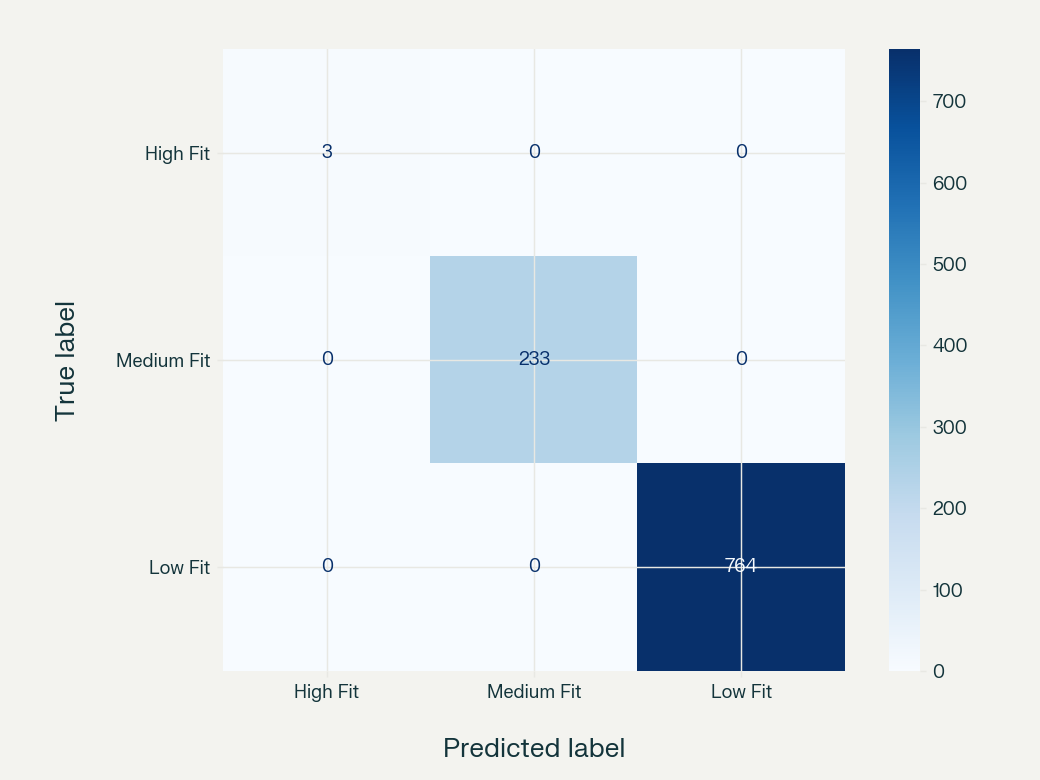

In [30]:
# Step 30: Prepare or inspect comparison
comparison=validation_comparison.merge(pd.DataFrame(metrics),on='model')
display(comparison)
display(pd.DataFrame(reports))
majority=y.loc[trainval_idx].mode()[0]
baseline=accuracy_score(y.loc[test_idx],[majority]*len(test_idx))
print('Majority-class baseline test accuracy:',baseline)
ConfusionMatrixDisplay(confusion_matrix(y.loc[test_idx],test_predictions[best_name],labels=LABELS),display_labels=LABELS).plot(cmap='Blues')
plt.title(best_name+' vs synthetic rule labels');plt.tight_layout();plt.savefig(OUT/'confusion_matrix.png',dpi=130);plt.close();_display(Image(filename=str(OUT/'confusion_matrix.png')))
rf=models['Random Forest'].named_steps['model']

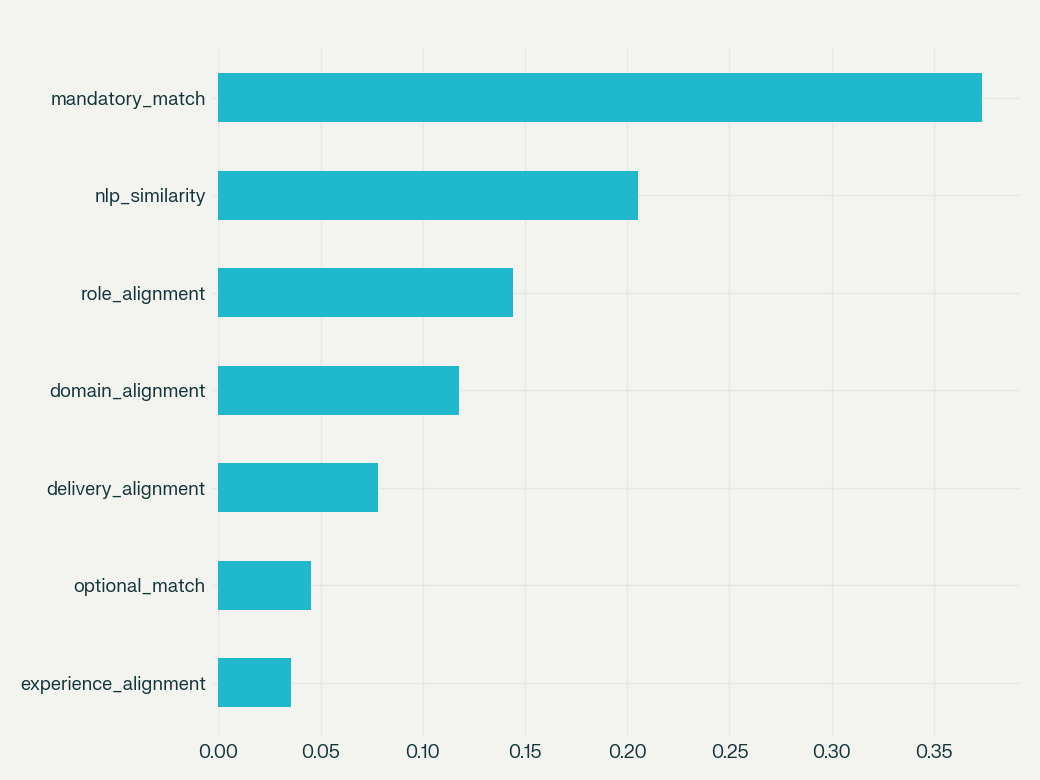

In [31]:
# Step 31: Prepare or inspect importance
importance=pd.Series(rf.feature_importances_,index=FEATURES+['nlp_similarity']).sort_values()
importance.plot.barh(title='Random Forest: reproduction of synthetic policy')
plt.tight_layout();plt.savefig(OUT/'policy_feature_importance.png',dpi=130);plt.close();_display(Image(filename=str(OUT/'policy_feature_importance.png')))
importance.rename('importance').to_csv(OUT/'policy_feature_importance.csv')
comparison.to_csv(OUT/'model_comparison.csv',index=False)
pd.DataFrame(reports).to_csv(OUT/'per_class_metrics.csv',index=False)

## 6. Sensitivity and limits
Compare the top five eligible candidates (or fewer when needed), rather than the entire eligible pool. Also measure order changes across the full eligible pool using rank correlation and average rank displacement. Deterministic candidate-ID tie-breaking makes comparisons repeatable. With fewer than two eligible candidates, stability is not meaningfully assessable.

These are stability checks, not independent validation. Actual precision@K, recall@K and NDCG need independent relevance judgments. Stable rankings can still be unsuitable.

In [32]:
# Step 32: Prepare or inspect sensitivity
sensitivity=[]

In [33]:
# Step 33: Run job processing
for job in JOBS:
    eligible=scored_jobs[job['id']].query('eligible').copy()
    n_eligible=len(eligible)
    k=min(5,n_eligible-1) if n_eligible>1 else 0
    base_order=eligible.sort_values(['ranking_score','candidate_id'],ascending=[False,True])
    base_ids=set(base_order.head(k).candidate_id)
    base_ranks=pd.Series(np.arange(1,n_eligible+1,dtype=float),index=base_order.candidate_id)
    for text_weight in [.1,.2,.3]:
        trial=eligible.assign(trial_score=(1-text_weight)*eligible.structural_score+100*text_weight*eligible.nlp_similarity)
        trial=trial.sort_values(['trial_score','candidate_id'],ascending=[False,True])
        trial_ids=set(trial.head(k).candidate_id)
        trial_ranks=pd.Series(np.arange(1,n_eligible+1,dtype=float),index=trial.candidate_id).reindex(base_ranks.index)
        sensitivity.append({'role':job['title'],'eligible_count':n_eligible,'text_weight':text_weight,'k':k,
                            'top_k_overlap':len(base_ids&trial_ids)/k if k else np.nan,
                            'rank_correlation':base_ranks.corr(trial_ranks) if n_eligible>1 else np.nan,
                            'mean_absolute_rank_change':float((base_ranks-trial_ranks).abs().mean()) if n_eligible>1 else np.nan,
                            'interpretation':'Assessable' if n_eligible>1 else 'Too few eligible candidates'})

In [34]:
# Step 34: Prepare or inspect sensitivity
sensitivity=pd.DataFrame(sensitivity)
display(sensitivity)
sensitivity.to_csv(OUT/'ranking_sensitivity.csv',index=False)
assert sensitivity.loc[sensitivity.eligible_count.gt(1),'k'].lt(sensitivity.loc[sensitivity.eligible_count.gt(1),'eligible_count']).all()
thresholds=pd.DataFrame([{'threshold':t,'high_fit_count':int((model_data.eligible&model_data.structural_score.ge(t)).sum())} for t in [75,80,85]])
display(thresholds)
thresholds.to_csv(OUT/'label_threshold_sensitivity.csv',index=False)

,role,eligible_count,text_weight,k,top_k_overlap,rank_correlation,mean_absolute_rank_change,interpretation
0,Senior Data Scientist,14,0.1,5,0.8,0.863736,1.428571,Assessable
1,Senior Data Scientist,14,0.2,5,1.0,1.000000,0.000000,Assessable
2,Senior Data Scientist,14,0.3,5,1.0,0.982418,0.428571,Assessable
3,Software Engineer,516,0.1,5,0.8,0.980670,19.496124,Assessable
4,Software Engineer,516,0.2,5,1.0,1.000000,0.000000,Assessable
5,Software Engineer,516,0.3,5,0.8,0.967668,26.387597,Assessable


,threshold,high_fit_count
0,75,14
1,80,14
2,85,14


## 7. Business report and configuration exports
The report uses actual computed findings, three candidate examples and ranking-sensitivity results. No claim of time savings, reduced bias, independently improved matching or calibrated probabilities is made.

Recruiter review is required even for eligible candidates. Protect candidate data, assess job relevance, support accessibility and corrections, and audit appropriate outcomes before deployment. Recruiter decisions are feedback, not automatically unbiased ground truth.

In [35]:
# Step 35: Prepare or inspect feature_definitions
feature_definitions=pd.DataFrame([{'feature':f,'structural_weight':w,'meaning':{
 'mandatory_match':'Exact normalized mandatory skill coverage',
 'experience_alignment':'Minimum experience coverage capped at one',
 'domain_alignment':'Soft declared-domain match',
 'role_alignment':'Soft related-title match',
 'delivery_alignment':'Mean supplied delivery/mentoring/stakeholder flags'}[f]} for f,w in weights.items()])
feature_definitions.to_csv(OUT/'feature_dictionary.csv',index=False)

In [36]:
# Step 36: Prepare or inspect config
config={'jobs':JOBS,'structural_weights':weights,'ranking_text_weight':.2,
        'synthetic_thresholds':{'high':80,'medium':50},'vocabulary':sorted(VOCAB),
        'aliases':ALIASES,'seed':SEED,'primary_ranking':'eligibility first, then rules + NLP',
        'note':'Illustrative policy, not independently validated suitability'}
(OUT/'configuration.json').write_text(json.dumps(config,indent=2),encoding='utf-8')

2412

In [37]:
# Step 37: Prepare or inspect report_lines
report_lines=[
 '# TalentBridge — Business Report',
 '', '## Executive summary',
 f'Analyzed {len(df):,} parsed profiles for two assumed roles. This is human screening support, not automatic selection or rejection.',
 role_summary.to_string(index=False),
 '', '## Data quality and EDA',
 *['- '+x for x in findings],
 'Missing qualifications are Unknown. Invalid numeric data, duplicate content and inconsistent profiles are flagged. No presentation-quality or institution-tier penalty affects suitability.',
 '', '## Matching approach and assumptions',
 'Required-skill coverage, experience, domain, related title and delivery indicators form a structural score. Final ranking is 80% structural and 20% TF-IDF similarity. Weights, requirements and thresholds are learner assumptions, not optimized or employer-approved.',
 'Skill normalization repairs unique adjacent transpositions and spacing variants against a frozen reviewed vocabulary; ambiguous terms are preserved for review. An audit file records every decision. Parsed skills do not establish proficiency.',
 'Structural weights prioritize explicit required skills, then minimum experience. Domain/title provide softer supporting evidence; unverified delivery flags receive a small weight. The 80:20 structural/text blend is a starting assumption, not an optimized choice.',
 'Eligibility requires mandatory skills and minimum experience. Eligible shortlists contain at most 50 people; remaining candidates go into a separate requirements-review queue. Data-review flags remain visible within the eligible group.',
 '', '## Model evaluation',
 f'{best_name} was selected using validation macro F1. Every model was then refitted on the same training+validation split and evaluated on the same untouched test set.',
 comparison.to_string(index=False),
 f'Majority-class baseline accuracy: {baseline:.3f}. Class-level metrics and the selected-model confusion matrix use the same final fits.',
 'Labels are structural-rule outputs. Reported metrics measure policy reproduction, not true hiring accuracy. Classifier scores are not blended into ranking.',
 '', '## Candidate examples',
 case_studies.to_string(index=False),
 '', '## Ranking sensitivity',
 sensitivity.to_string(index=False),
 'Top-K overlap tests membership; rank correlation and displacement test ordering. These are internal stability checks, not independently validated relevance.',
 '', '## Recruiter recommendations',
 '1. Review eligible candidates in ranking order; verify projects, skill depth and experience before any interview decision.',
 '2. Review missing requirements and unresolved skills separately; missing parsed evidence is not proof of inability.',
 '3. Ask hiring managers to approve requirements, vocabulary, weights and thresholds. Clarify reported resume-length semantics.',
 '4. Obtain independent, blinded relevance judgments for candidate–job pairs, including borderline and excluded profiles, before measuring real precision@K, recall@K and NDCG.',
 '5. Pilot with oversight and track screening time, agreement and progression. Audit appropriate fairness/accessibility outcomes, protect candidate data and permit corrections.',
 '', '## Limitations',
 'Two illustrative jobs do not establish broad generalization. No verified proficiency, hiring outcomes or independent suitability labels are supplied. Template reuse limits text discrimination. No separate certification field is available. Skill normalization covers specified noise patterns, not every possible typo.',
 'Weights and review thresholds remain assumptions. Rule-label classification is intentionally circular policy emulation. High model metrics and stable rankings do not establish usefulness, fairness or business uplift.',
 '', '## Submission deliverables',
 'Executed notebook; cleaned dataset; validation and normalization audits; feature dictionary and configuration; EDA; model comparison and class reports; confusion matrix; policy feature importance; role-specific scores, explanations, eligible shortlists and review queues; sensitivity tables; this report.'
]

In [38]:
# Step 38: Prepare or inspect report
report=chr(10).join(report_lines)
(OUT/'business_report.md').write_text(report,encoding='utf-8')
assert (OUT/'business_report.md').stat().st_size>0
assert not any(c in FEATURES for c in ['candidate_name','institution_tier','keyword_density_score'])
print('Report exported. Output file count:',len(list(OUT.iterdir())))

Report exported. Output file count: 22


## Final checklist
- Cleaned data, validation summary and skill audit exported.
- Scores, matching explanations and role-specific eligible/review queues exported.
- Three classifiers compared with clean train/validation/test text processing.
- No unsupported ML hybrid or hiring-accuracy claim.
- Model tables, confusion matrix and feature importance use consistent final fits.
- EDA, sensitivity, assumptions, limitations and business report included.

Before submission, inspect skill_normalization_audit.csv, read the report and explain the assumptions in your own words. Real-world validity remains untested. Source basis: supplied capstone brief, data dictionary, original CSV and prior notebooks.